# **Project Name**    - HOTEL RECOMMENDATION SYSTEM



##### **Contribution**    - Individual - Someshwar M


# **Project Summary -**

In this project, the aim is to design a recommendation system which will recommend hotels based on the travel preferences of the users and based on the historical travel data. The data will include details related to the users, hotels, destinations, travel duration, prices, cost of the trips, and dates of travel. The idea is to analyze travel patterns and the preferences of the users and make recommendations for hotels.

Data exploration and cleaning will be done along with feature analysis and visualization in order to find out the most preferred hotels, destinations, patterns in travel duration and also their spending behavior. Recommendations will be generated for the users based on their travel history and the preferences and destinations chosen by them in the past.

At last, the recommendation will be put in a Streamlit web app where the users can explore the hotel recommendations and visualize the insights drawn from the travel data.

# **GitHub Link -**

https://github.com/Someshwar24/Flight-Price-Prediction-MLOps

# **Problem Statement**


There are various factors involved in the selection of a hotel such as location, hotel cost, number of days to spend at the hotel, and previous travel preferences of the users. Selecting an appropriate hotel within the available budget may not be easy for travelers. To help with this, a Hotel Recommendation System is created using past travel information.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

### Dataset Loading

In [ ]:
# Load Dataset
original_df = pd.read_csv("hotels.csv")
df = original_df.copy()

### Dataset First View

In [ ]:
# Dataset First Look
df.head()

### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
df.shape

### Dataset Information

In [ ]:
# Dataset Info
df.info()

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
df.duplicated().sum()

#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
df.isnull().sum()

### What did you know about your dataset?

There are 40,552 rows of travel data with 8 columns representing travel identifier, user information, hotel information, destination, number of days stayed, travel price, total travel cost, and travel dates. There are no duplicated rows and missing values at the preliminary examination stage. userCode, name, and place would be used to identify historical preferences of users for the hotel and destinations, while days, price, total, and date can be used for future travels.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
df.columns

In [ ]:
# Dataset Describe
df.describe()

### Variables Description

There are eight variables included in the data which involve information about travel history and hotel recommendations. In the data, travelCode and userCode are the identifiers for travel and users respectively. name is the variable that includes the hotel name, whereas place is for destinations. days shows the number of days of stay, price for the daily cost of the hotel and total for the total expense. date is the travel date.


### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for column in df.columns:
  print(column, ":" , df[column].nunique())

## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year

df[["date", "month", "year"]].head()

In [ ]:
df[["days", "price", "total"]].describe()

In [ ]:
print("Top 10 hotels:\n", df["name"].value_counts().head(10))
print("\nTop 10 destinations:\n", df["place"].value_counts().head(10))

## ***4. Data Vizualization***

#### Chart - 1

In [ ]:
#1 - Top 10 hotels by travel records

top_hotels = df["name"].value_counts().head(10).reset_index()
top_hotels.columns = ["Hotel", "Count"]

sns.barplot(data=top_hotels, x="Count", y="Hotel")
plt.title("Top 10 Most Frequently Recorded Hotels")
plt.xlabel("Number of Travel Records")
plt.ylabel("Hotel")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare hotel frequencies.

##### 2. What is/are the insight(s) found from the chart?

It identifies the hotels appearing most frequently in the travel records.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Popular hotels can be prioritized in recommendations, although frequency alone does not establish hotel quality or customer satisfaction.

#### Chart - 2

In [ ]:
#2 - Top 10 destinations
top_destinations = df["place"].value_counts().head(10).reset_index()
top_destinations.columns = ["Destination", "Count"]

sns.barplot(data=top_destinations, x="Count", y="Destination")
plt.title("Top 10 Most Frequently Visited Destinations")
plt.xlabel("Number of Travel Records")
plt.ylabel("Destination")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare the frequency of different destinations.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies the destinations appearing most frequently in the historical travel records.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Popular destinations can guide hotel recommendations and travel planning. However, less frequent destinations may still be relevant to users with specific preferences.

#### Chart - 3

In [ ]:
#3 - Distribution of stay duration
stay_counts = df["days"].value_counts().sort_index().reset_index()
stay_counts.columns = ["Days", "Count"]

sns.barplot(data=stay_counts, x="Days", y="Count")
plt.title("Distribution of Hotel Stay Duration")
plt.xlabel("Number of Days")
plt.ylabel("Number of Travel Records")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart clearly compares the frequency of different stay durations.

##### 2. What is/are the insight(s) found from the chart?

The chart shows which stay durations are most common in the dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding typical stay durations can help tailor hotel recommendations to users' travel patterns and support more relevant trip planning.

#### Chart - 4

In [ ]:
#4 - Average hotel price by destination
destination_prices = df.groupby("place")["price"].mean().sort_values(ascending=False).head(10).reset_index()
destination_prices.columns = ["Destination", "Average Price"]

sns.barplot(data=destination_prices, x="Average Price", y="Destination")
plt.title("Top 10 Destinations by Average Hotel Price")
plt.xlabel("Average Daily Hotel Price")
plt.ylabel("Destination")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare average hotel prices across destinations.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies destinations with the highest average daily hotel prices in the dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Price comparisons can help users discover destinations that fit their budgets and support more personalized hotel recommendations. However, higher prices do not necessarily indicate better quality.

## ***5. Feature Engineering & Data Pre-processing***

In [ ]:
# Select columns needed for recommendations
recommendation_df = df[["userCode", "name", "place", "price", "days"]].copy()

recommendation_df.head()

In [ ]:
print("Number of users:", recommendation_df["userCode"].nunique())
print("Number of hotels:", recommendation_df["name"].nunique())
print("Number of destinations:", recommendation_df["place"].nunique())

print("\nRepeated user-hotel combinations:")
display(
    recommendation_df.groupby(["userCode", "name"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(10)
)

In [ ]:
def recommend_hotels(destination, budget, top_n=5):

    hotels = df[
        (df["place"].str.lower() == destination.lower()) &
        (df["price"] <= budget)
    ]

    recommendations = (
        hotels.groupby("name")
        .agg(
            Average_Price=("price", "mean"),
            Popularity=("name", "count")
        )
        .sort_values("Popularity", ascending=False)
        .head(top_n)
        .reset_index()
    )

    return recommendations

In [ ]:
recommend_hotels(
    destination="Salvador (BH)",
    budget=300,
    top_n=5
)

In [ ]:
hotel_options = (
    df.groupby("place")["name"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Number_of_Hotels")
)

display(hotel_options.head(10))

## ***6.*** ***Streamlit App for Hotel Recommendations***

In [ ]:
!pip install streamlit

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd

df = pd.read_csv("/content/hotels.csv")

def recommend_hotels(destination, budget, top_n=5):
    hotels = df[
        (df["place"].str.lower() == destination.lower()) &
        (df["price"] <= budget)
    ]

    recommendations = (
        hotels.groupby("name")
        .agg(
            Average_Price=("price", "mean"),
            Popularity=("name", "count")
        )
        .sort_values("Popularity", ascending=False)
        .head(top_n)
        .reset_index()
    )

    return recommendations

st.title("Hotel Recommendation System")
st.write("Find hotels based on your destination and budget.")

destination = st.selectbox(
    "Select destination",
    sorted(df["place"].dropna().unique())
)

budget = st.number_input(
    "Maximum daily hotel price",
    min_value=0.0,
    value=300.0
)

if st.button("Recommend Hotels"):
    result = recommend_hotels(destination, budget)

    if result.empty:
        st.warning("No hotels found. Try increasing your budget.")
    else:
        st.success("Recommended hotels")
        st.dataframe(result, use_container_width=True)

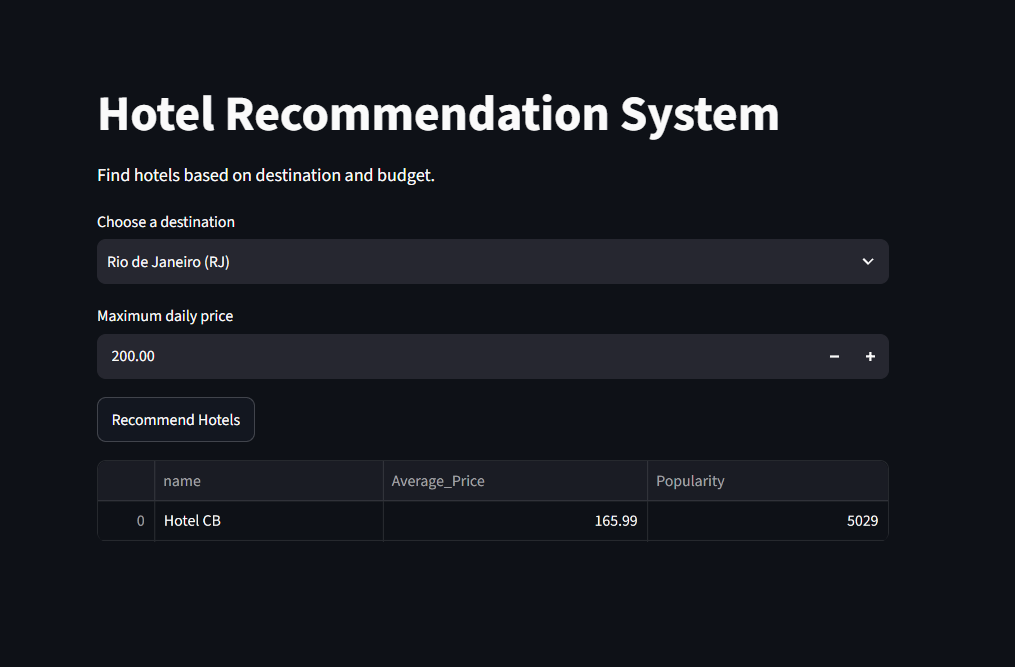

# **Conclusion**

The Hotel Recommendation System recommends the hotels taking into consideration the destination chosen by the user, their budget, and also the popularity of the hotels in the past. Developed through the use of Python, Pandas, and Streamlit, the application has an easy-to-use interface where users can explore hotels.